In [3]:
import pandas as pd

# Load dataset
df = pd.read_excel("CitizenGrievance.xlsx")

# Display first five records
print("First five records:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Identify structured and unstructured columns
structured_columns = ['Complaint_id', 'State', 'Date']
unstructured_columns = ['Complaint_Description']

print("\nStructured Data:")
print(df[structured_columns].head())

print("\nUnstructured Data:")
print(df[unstructured_columns].head())

First five records:
  Complaint_id                              Complaint_Description  \
0    GRV101340  Eve teasing Adhartal area mein badh gayi hai, ...   
1    GRV102878  à¤¶à¥à¤°à¤®à¤¿à¤• à¤•à¤¾à¤°à¥à¤¡ Ranchi à¤®à...   
2    GRV100497  Dear officer, à¤¸à¤¡à¤¼à¤• à¤ªà¤° à¤¬à¤¿à¤¨à¤¾...   
3    GRV100019  à¤ªà¤¿à¤›à¤²à¥‡ a month à¤¸à¥‡ à¤¹à¤®à¤¾à¤°à¥‡...   
4    GRV101868  Namaste sir, à¤¸à¤°à¤•à¤¾à¤°à¥€ à¤¸à¥à¤•à¥‚à¤...   

               Department       Date        State ResolutionDate  
0  Police & Law and Order 2025-02-17  Maharashtra     2025-02-28  
1     Employment & Labour 2025-07-02      Manipur     2025-07-31  
2  Roads & Infrastructure 2025-08-30        Bihar     2025-09-26  
3            Water Supply 2025-09-22    Rajasthan     2025-10-06  
4     Education & Schools 2025-04-05       Punjab     2025-04-17  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1571 entries, 0 to 1570
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dt

In [6]:
# Check missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing structured data
df['Complaint_id'] = df['Complaint_id'].fillna('Unknown')
df['State'] = df['State'].fillna('Unknown')

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Fill missing dates
df['Date'] = df['Date'].fillna(pd.Timestamp('2025-01-01'))

# Fill missing complaint descriptions
df['Complaint_Description'] = df['Complaint_Description'].fillna(
    'No Description Provided'
)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display cleaned dataset
print("\nCleaned Dataset:")
print(df.head())

Missing values before cleaning:
Complaint_id             0
Complaint_Description    0
Department               0
Date                     0
State                    0
ResolutionDate           0
dtype: int64

Missing values after cleaning:
Complaint_id             0
Complaint_Description    0
Department               0
Date                     0
State                    0
ResolutionDate           0
dtype: int64

Cleaned Dataset:
  Complaint_id                              Complaint_Description  \
0    GRV101340  Eve teasing Adhartal area mein badh gayi hai, ...   
1    GRV102878  à¤¶à¥à¤°à¤®à¤¿à¤• à¤•à¤¾à¤°à¥à¤¡ Ranchi à¤®à...   
2    GRV100497  Dear officer, à¤¸à¤¡à¤¼à¤• à¤ªà¤° à¤¬à¤¿à¤¨à¤¾...   
3    GRV100019  à¤ªà¤¿à¤›à¤²à¥‡ a month à¤¸à¥‡ à¤¹à¤®à¤¾à¤°à¥‡...   
4    GRV101868  Namaste sir, à¤¸à¤°à¤•à¤¾à¤°à¥€ à¤¸à¥à¤•à¥‚à¤...   

               Department       Date        State ResolutionDate  
0  Police & Law and Order 2025-02-17  Maharashtra     2025-02-28  
1     Employment & 

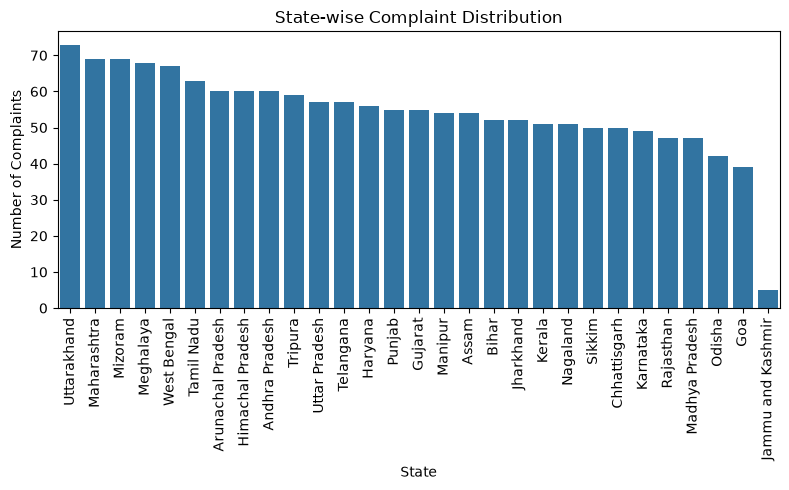

Total Number of Complaints: 1571


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count complaints state-wise
state_counts = df['State'].value_counts()

# Generate bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=state_counts.index, y=state_counts.values)

plt.title('State-wise Complaint Distribution')
plt.xlabel('State')
plt.ylabel('Number of Complaints')
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()
# Calculate total number of complaints
total_complaints = len(df)

# Display result
print("Total Number of Complaints:", total_complaints)

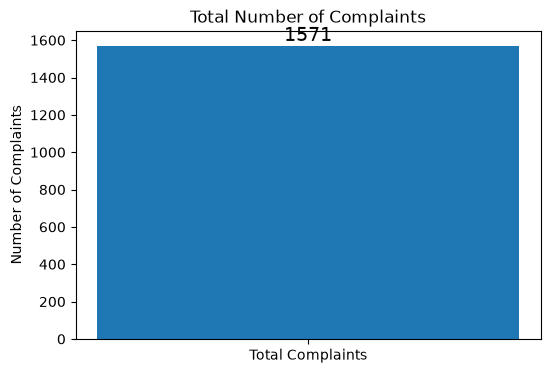

In [8]:
total_complaints = len(df)

plt.figure(figsize=(6, 4))
plt.bar(['Total Complaints'], [total_complaints])

plt.title('Total Number of Complaints')
plt.ylabel('Number of Complaints')

plt.text(0, total_complaints, str(total_complaints),
         ha='center', va='bottom', fontsize=14)

plt.show()

In [9]:
import seaborn as sns

# Count complaints department-wise
top5_departments = df['Department'].value_counts().head(5)

# Display Top 5 Departments
print("Top 5 Departments Receiving Highest Complaints:")
print(top5_departments)

Top 5 Departments Receiving Highest Complaints:
Department
Employment & Labour             133
Education & Schools             124
Land Records & Revenue          124
Corruption & Bribery            122
Banking & Financial Services    118
Name: count, dtype: int64


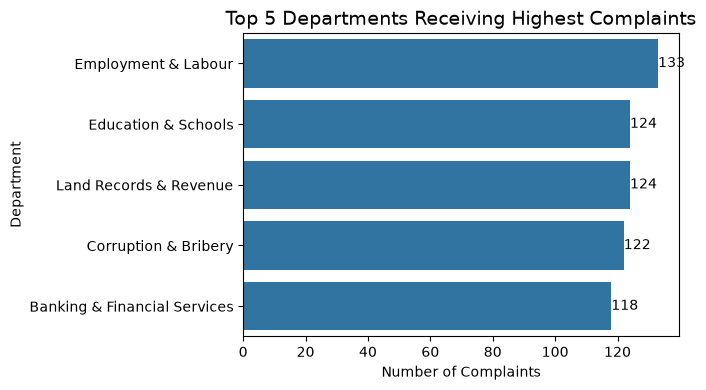

In [10]:
plt.figure(figsize=(7, 4))

sns.barplot(
    x=top5_departments.values,
    y=top5_departments.index
)

plt.title('Top 5 Departments Receiving Highest Complaints',
          fontsize=14)

plt.xlabel('Number of Complaints')
plt.ylabel('Department')

# Display complaint counts on bars
for i, value in enumerate(top5_departments.values):
    plt.text(value, i, str(value), va='center', ha='left')

plt.tight_layout()
plt.show()

Average Complaint Resolution Time: 15.51 Days


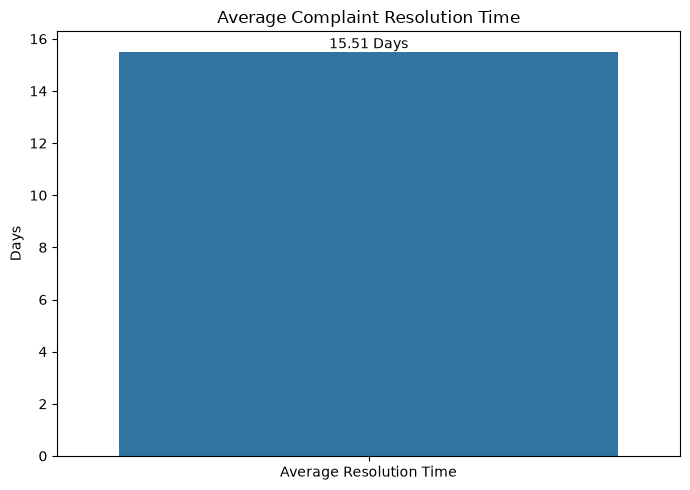

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert columns into datetime format
df['Complaint Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Resolution Date'] = pd.to_datetime(df['ResolutionDate'], errors='coerce')

# Calculate resolution time in days
df['Resolution Time'] = (
    df['Resolution Date'] - df['Complaint Date']
).dt.days

# Calculate average resolution time
avg_days = df['Resolution Time'].dropna().mean()

print("Average Complaint Resolution Time:",
      round(avg_days, 2), "Days")

# Visualization
plt.figure(figsize=(7, 5))

sns.barplot(x=['Average Resolution Time'], y=[avg_days])

plt.title('Average Complaint Resolution Time')
plt.ylabel('Days')

plt.text(0, avg_days, f'{avg_days:.2f} Days',
         ha='center', va='bottom')

plt.tight_layout()
plt.show()
